In [ ]:
!pip install evaluate scikit-learn

In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer,DataCollatorWithPadding,AutoModelForSequenceClassification
from transformers import TrainingArguments,Trainer
import evaluate
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
import torch
import torch.nn as nn
import numpy as np

In [ ]:
dataset=load_dataset("fancyzhx/ag_news")


In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

In [ ]:
print(dataset['train'].features)
print(dataset['train'][0])
print(dataset['train'].column_names)

{'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}
['text', 'label']


In [ ]:
dataset['train'],dataset['validation']=dataset['train'].train_test_split(test_size=0.1,
                                                                         shuffle=True,
                                                                         stratify_by_column='label'
                                                                         ,seed=122).values()

In [ ]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 108000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 12000
    })
})

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

In [ ]:
device

device(type='cuda')

In [ ]:
checkpoint="bert-base-uncased"
tokenizer=AutoTokenizer.from_pretrained(checkpoint)

In [ ]:
def tokenizer_fun(batch):
  return tokenizer(batch['text'],
                   truncation=True)

In [ ]:
tokenized_data= dataset.map(tokenizer_fun,
                            batched=True)

In [ ]:
tokenized_data=tokenized_data.remove_columns(['text'])
tokenized_data

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 108000
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 12000
    })
})

In [ ]:
tokenized_data.set_format('torch',
                          columns=['input_ids',
                                   'attention_mask',
                                   'label'])

In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"

)

In [ ]:
data_collator

DataCollatorWithPadding(tokenizer=BertTokenizer(name_or_path='bert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}), padding=True, max_length=None, pad_to_multiple_of=None, return_tensors='pt')

In [ ]:
model_trainer=AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=4
)
model_manual=AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=4
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:

acc = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": acc.compute(predictions=preds, references=labels)["accuracy"],
        "f1": f1.compute(predictions=preds, references=labels, average="macro")["f1"],
    }

In [ ]:
training_args=TrainingArguments(
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    learning_rate=2e-5,
    weight_decay=0.01,
    lr_scheduler_type="linear",
    fp16=True,
    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True
)

In [ ]:
model_trainer.to(device)
model_manual.to(device)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [ ]:
trainer=Trainer(
    model=model_trainer,
    args=training_args,
    train_dataset=tokenized_data['train'],
    eval_dataset=tokenized_data['validation'],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics

)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.230199,0.188530,0.939167,0.939200
2,0.136913,0.185061,0.946917,0.946811
3,0.085350,0.224990,0.946333,0.946320


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=20250, training_loss=0.15082050238715278, metrics={'train_runtime': 2152.7406, 'train_samples_per_second': 150.506, 'train_steps_per_second': 9.407, 'total_flos': 1.6215595301008896e+16, 'train_loss': 0.15082050238715278, 'epoch': 3.0})

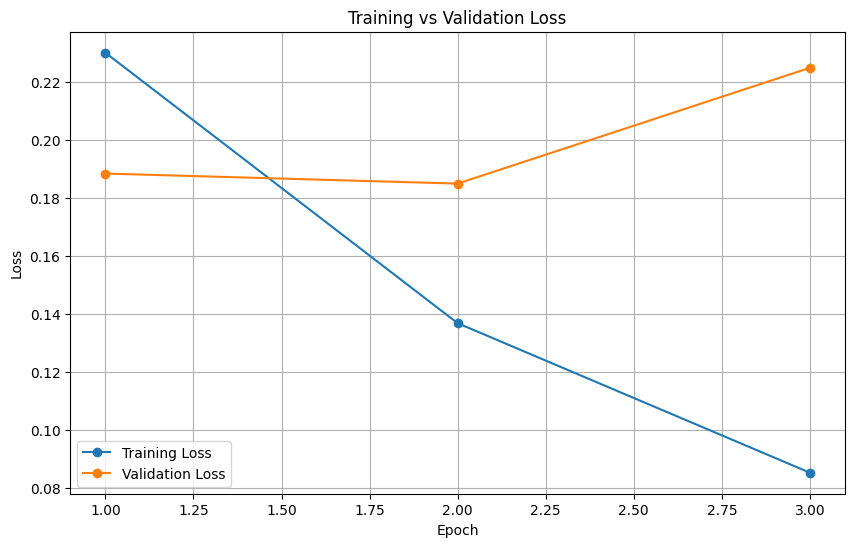

In [ ]:
history = trainer.state.log_history

train_epochs = []
train_loss = []

val_epochs = []
val_loss = []

for log in history:

    if "loss" in log and "epoch" in log:
        train_epochs.append(log["epoch"])
        train_loss.append(log["loss"])

    if "eval_loss" in log and "epoch" in log:
        val_epochs.append(log["epoch"])
        val_loss.append(log["eval_loss"])


plt.figure(figsize=(10, 6))

plt.plot(
    train_epochs,
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    val_epochs,
    val_loss,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

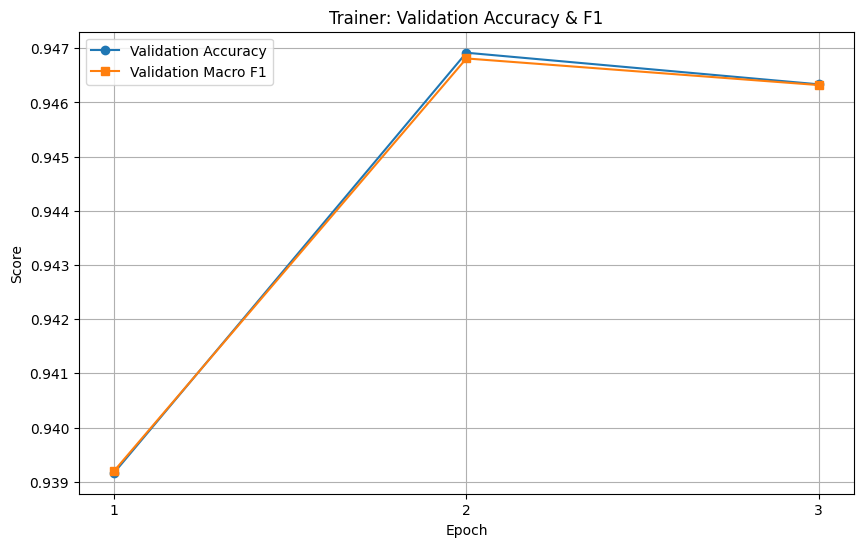

In [ ]:


history = trainer.state.log_history

epochs, val_acc, val_f1 = [], [], []
for log in history:
    if "eval_accuracy" in log:
        epochs.append(log["epoch"])
        val_acc.append(log["eval_accuracy"])
        val_f1.append(log["eval_f1"])

plt.figure(figsize=(10, 6))
plt.plot(epochs, val_acc, marker="o", label="Validation Accuracy")
plt.plot(epochs, val_f1, marker="s", label="Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Trainer: Validation Accuracy & F1")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
train_loader=DataLoader(tokenized_data['train'],
                batch_size=16,
                shuffle=True,
                collate_fn=data_collator,
                pin_memory=True
                )
validation_loader=DataLoader(tokenized_data['validation'],
                batch_size=16,
                shuffle=False,
                collate_fn=data_collator,
                pin_memory=True
                )


In [ ]:
optimizer = AdamW(
    model_manual.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

In [ ]:
num_epochs = 3
total_steps = len(train_loader) * num_epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)

In [ ]:
train_losses, val_losses, val_accs, val_f1s = [], [], [], []
best_val_loss = float("inf")
for epoch in range(num_epochs):
    model_manual.train()
    total_train_loss=0

    for batch in train_loader:
        batch={k:v.to(device) for k,v in batch.items()}
        outputs=model_manual(**batch)
        loss = outputs.loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_train_loss+=loss.item()
    train_loss=total_train_loss/len(train_loader)
    train_losses.append(train_loss)
    print(f"train_loss: {train_loss}")


    '''
      =====================
      Model evaluation
      =====================
    '''
    model_manual.eval()

    total_val_loss = 0
    all_preds, all_labels = [], []
    for batch in validation_loader:
        batch={k:v.to(device) for k,v in batch.items()}
        with torch.no_grad():
          outputs=model_manual(**batch)
          loss = outputs.loss
          total_val_loss+=loss.item()
          preds = torch.argmax(outputs.logits, dim=-1)
          all_preds.extend(preds.cpu().numpy())
          all_labels.extend(batch["labels"].cpu().numpy())

    val_loss=total_val_loss/len(validation_loader)
    val_acc = acc.compute(predictions=all_preds, references=all_labels)["accuracy"]
    val_f1 = f1.compute(predictions=all_preds, references=all_labels, average="macro")["f1"]

    val_losses.append(val_loss)
    val_accs.append(val_acc)
    val_f1s.append(val_f1)

    print(f"epoch {epoch+1}: train_loss={train_loss:.4f} | "
          f"val_loss={val_loss:.4f} | acc={val_acc:.4f} | f1={val_f1:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model_manual.state_dict(), "best_manual.pt")


model_manual.load_state_dict(torch.load("best_manual.pt"))



train_loss: 0.27122302581473356
epoch 1: train_loss=0.2712 | val_loss=0.1648 | acc=0.9426 | f1=0.9425
train_loss: 0.1275886127837692
epoch 2: train_loss=0.1276 | val_loss=0.1564 | acc=0.9460 | f1=0.9459
train_loss: 0.07190759915280742
epoch 3: train_loss=0.0719 | val_loss=0.1669 | acc=0.9457 | f1=0.9458


<All keys matched successfully>

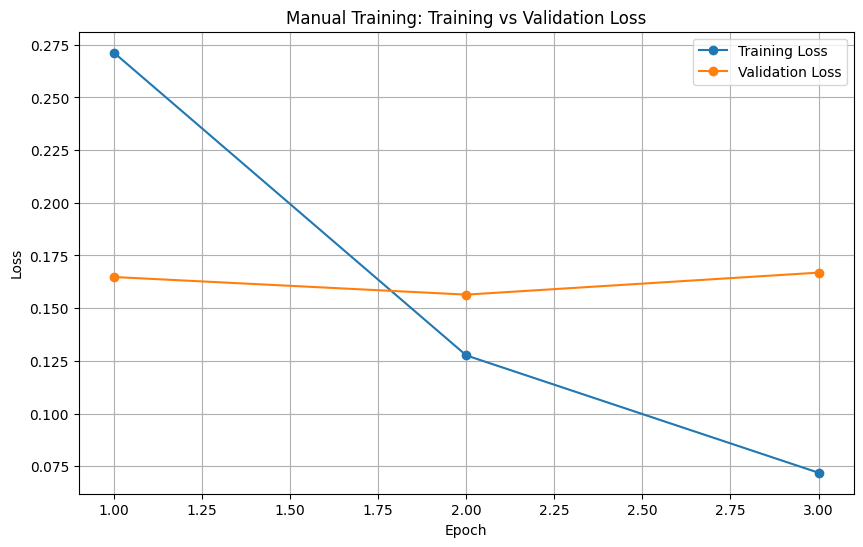

In [ ]:

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Manual Training: Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

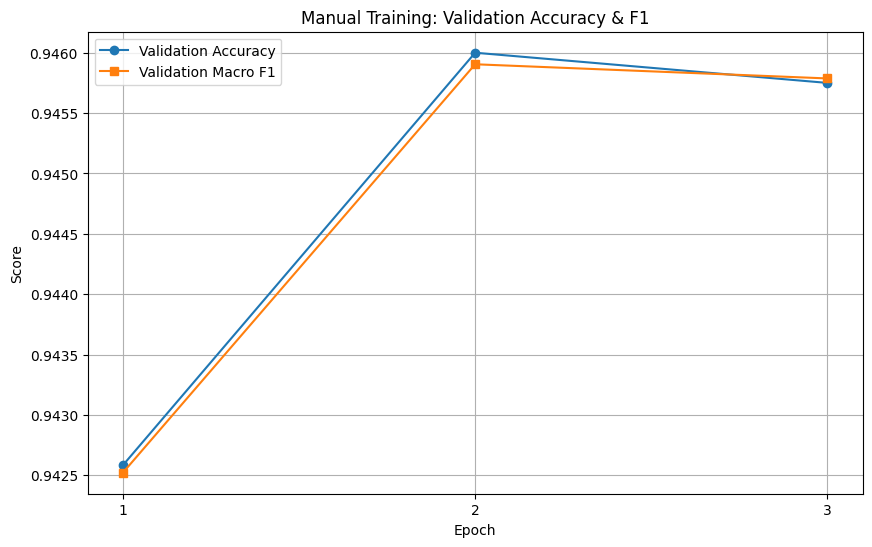

In [ ]:
epochs = range(1, len(val_accs) + 1)

plt.figure(figsize=(10, 6))
plt.plot(epochs, val_accs, marker="o", label="Validation Accuracy")
plt.plot(epochs, val_f1s, marker="s", label="Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Manual Training: Validation Accuracy & F1")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.show()